# Line Density of Many Series (datashader)

**Family:** Interactive, animated & big data &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Interactive, animated & big data:* What-if sliders, linked views, animation and million-point rendering. Use these when exploration or motion adds understanding that a static chart cannot.

## Design purpose

Draws thousands of time series at once by counting how many lines pass through each pixel. The "spaghetti" becomes a density field that shows where paths typically go, how wide the spread is, and where unusual paths escape, which thousands of overlapping lines cannot show.

## When to use

- Show thousands of simulated paths (Monte Carlo, bootstrap, scenario sets)
- Show many real series at once (all stocks in an index, sensors, user sessions)
- Reveal multimodal outcomes, such as paths that split into two regimes

## Avoid when

- There are fewer than ~50 series (highlight a few and gray the rest)
- Each line's identity matters (density loses identity)

## Alternatives

- Fan chart (percentile bands only)
- Highlighted spaghetti (gray context with a few colored lines)
- Ridgeline of the final-value distribution

## Design tips

- Overlay a few summary lines (median, 5th and 95th percentiles) in a contrasting color with direct labels
- Use a log color scale; most of the ink sits near the median
- Requires the advanced extras: `pip install -r requirements-advanced.txt`

## Example

2,000 simulated one-year price paths (geometric Brownian motion, 8% drift, 16% volatility, with a 15% chance of a six-week crash of about 35%), rendered as a line-density image.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import datashader as ds
from matplotlib.colors import LogNorm

### Data

In [2]:
rng = np.random.default_rng(12)
n_paths, n_days = 2000, 252
dt = 1 / 252
mu, sigma = 0.08, 0.16
shocks = rng.normal((mu - sigma**2 / 2) * dt, sigma * np.sqrt(dt), (n_paths, n_days))
crash = rng.random(n_paths) < 0.15                          # crash regime from day ~90
shocks[crash, 90:120] += rng.normal(-0.014, 0.004, (crash.sum(), 30))   # ~-35% over six weeks
paths = 100 * np.exp(np.cumsum(shocks, axis=1))
paths = np.hstack([np.full((n_paths, 1), 100.0), paths])
days = np.arange(n_days + 1)
# Long format, one NaN row between paths so lines are not joined.
x = np.tile(np.append(days, np.nan), n_paths)
y = np.hstack([np.append(p, np.nan) for p in paths])
lines = pd.DataFrame({"day": x, "price": y})
pd.Series(paths[:, -1]).describe(percentiles=[0.05, 0.5, 0.95]).round(1)

count    2000.0
mean      102.0
std        21.5
min        44.5
5%         65.0
50%       102.0
95%       136.8
max       176.8
dtype: float64

### Plot

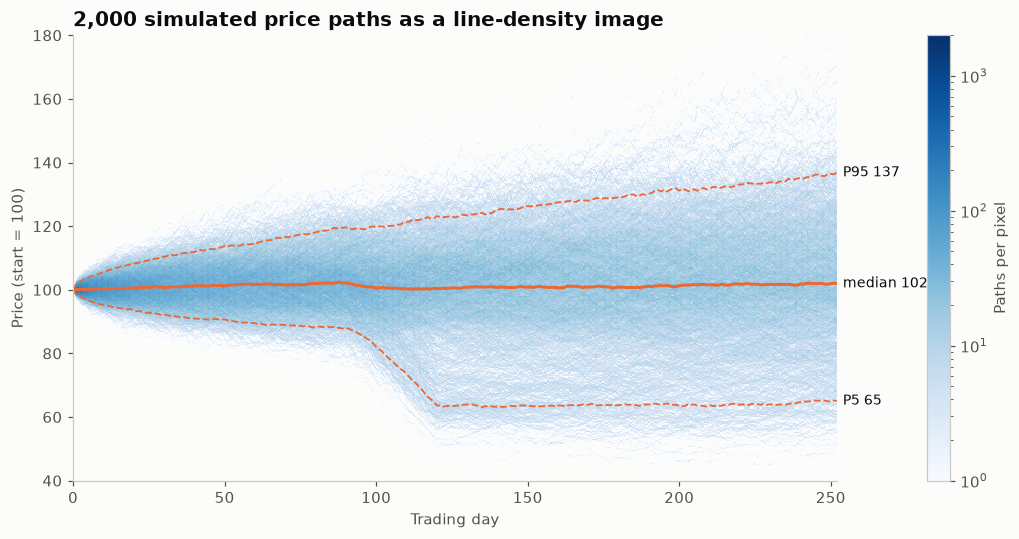

In [3]:
x_range, y_range = (0, n_days), (40, 180)
canvas = ds.Canvas(plot_width=900, plot_height=420, x_range=x_range, y_range=y_range)
density = canvas.line(lines, "day", "price", agg=ds.count()).values.astype(float)
density[density == 0] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(density, origin="lower", extent=[*x_range, *y_range], aspect="auto",
               cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=np.nanmax(density)), interpolation="nearest")
for q, style in [(50, "-"), (5, "--"), (95, "--")]:
    line = np.percentile(paths, q, axis=0)
    ax.plot(days, line, color=PALETTE[1], linewidth=2 if q == 50 else 1.2, linestyle=style)
    ax.text(n_days + 2, line[-1], f"{'median' if q == 50 else f'P{q}'} {line[-1]:.0f}",
            va="center", fontsize=9, color="#0b0b0b")
ax.set_xlim(*x_range)
ax.set_ylim(*y_range)
ax.grid(False)
ax.set_xlabel("Trading day")
ax.set_ylabel("Price (start = 100)")
ax.set_title(f"{n_paths:,} simulated price paths as a line-density image")
fig.colorbar(im, ax=ax, label="Paths per pixel", pad=0.09)
fig.tight_layout()
plt.show()

## How to read it

The dark core is where most paths travel; it fans out over the year. A second, fainter branch falls away below: the crash-regime paths, which a percentile fan would blur into one wide band. The orange lines mark the median and the 5th–95th percentile range.

---
Standalone script: [`datashader_timeseries.py`](datashader_timeseries.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)